# 손글씨 숫자 분류 - 딥러닝(Keras) 버전



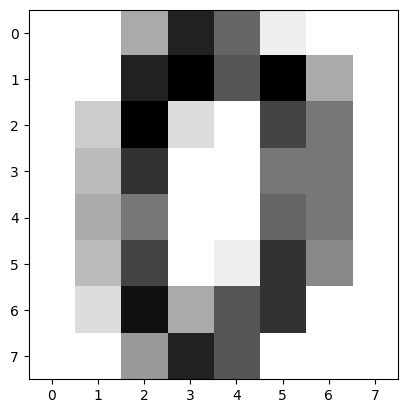

In [25]:
#데이터 불러오기
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

digits = datasets.load_digits()
plt.imshow(digits.images[0], cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

In [26]:
# 데이터 전처리
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# 픽셀값(0~16)을 0~1 범위로 정규화 -> 신경망 학습이 안정적
data = data / 16.0

In [27]:
# 데이터 훈련 및 분할
X_train, X_test, y_train, y_test = train_test_split(data, digits.target, test_size=0.2, random_state=42)

In [28]:
# 원-핫 인코딩: 3 -> [0,0,0,1,0,0,0,0,0,0]
from tensorflow.keras.utils import to_categorical
y_train_oh = to_categorical(y_train, num_classes=10)
y_test_oh  = to_categorical(y_test, num_classes=10)
print(y_train[0], "->", y_train_oh[0])

6 -> [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


In [29]:
# 모델 구성 (다층 퍼셉트론, MLP)
model = keras.Sequential([
    layers.Input(shape=(64,)),             # 8x8 = 64개 픽셀
    layers.Dense(128, activation='relu'),  # 은닉층 1
    layers.Dropout(0.2),                   # 과적합 방지
    layers.Dense(64, activation='relu'),   # 은닉층 2
    layers.Dense(10, activation='softmax') # 출력층: 0~9 각 숫자의 확률
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',  # 원-핫 레이블 사용
              metrics=['accuracy'])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# 모델 학습
history = model.fit(X_train, y_train_oh,
                    epochs=30,
                    batch_size=32,
                    validation_split=0.2,
                    verbose=1)
print("학습 완료")

Epoch 1/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3812 - loss: 2.0080 - val_accuracy: 0.7153 - val_loss: 1.5947
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7763 - loss: 1.1981 - val_accuracy: 0.8576 - val_loss: 0.7723
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8703 - loss: 0.6249 - val_accuracy: 0.9028 - val_loss: 0.4388
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9077 - loss: 0.3907 - val_accuracy: 0.8958 - val_loss: 0.3354
Epoch 5/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9199 - loss: 0.3080 - val_accuracy: 0.9271 - val_loss: 0.2792
Epoch 6/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9260 - loss: 0.2559 - val_accuracy: 0.9340 - val_loss: 0.2526
Epoch 7/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9460 - loss: 0.2115 - val_accuracy: 0.9236 - val_loss: 0.2407
Epoch 8/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9513 - loss: 0.1867 - val_accuracy: 0.9479 - val_loss

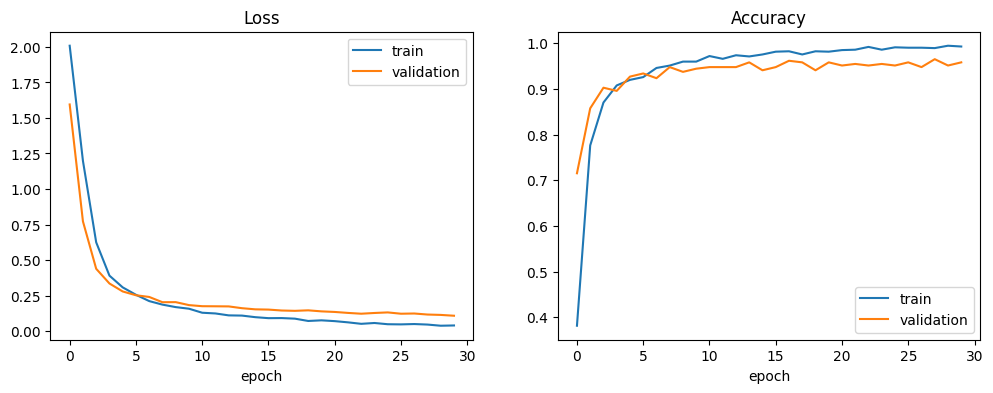

In [31]:
# 학습 과정 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['loss'], label='train')
ax1.plot(history.history['val_loss'], label='validation')
ax1.set_title('Loss'); ax1.set_xlabel('epoch'); ax1.legend()
ax2.plot(history.history['accuracy'], label='train')
ax2.plot(history.history['val_accuracy'], label='validation')
ax2.set_title('Accuracy'); ax2.set_xlabel('epoch'); ax2.legend()
plt.show()

In [32]:
# 예측 및 평가
y_prob = model.predict(X_test, verbose=0)  # 각 클래스별 확률 (n, 10)
y_pred = np.argmax(y_prob, axis=1)         # 가장 확률이 높은 클래스 선택
print("정확도:", metrics.accuracy_score(y_test, y_pred))

정확도: 0.9694444444444444


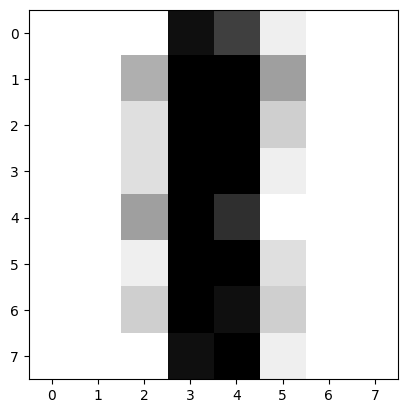

예측값: 1
실제값: 1


In [23]:
# 최종 결과
plt.imshow(X_test[10].reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()
print("예측값:", y_pred[10])
print("실제값:", y_test[10])

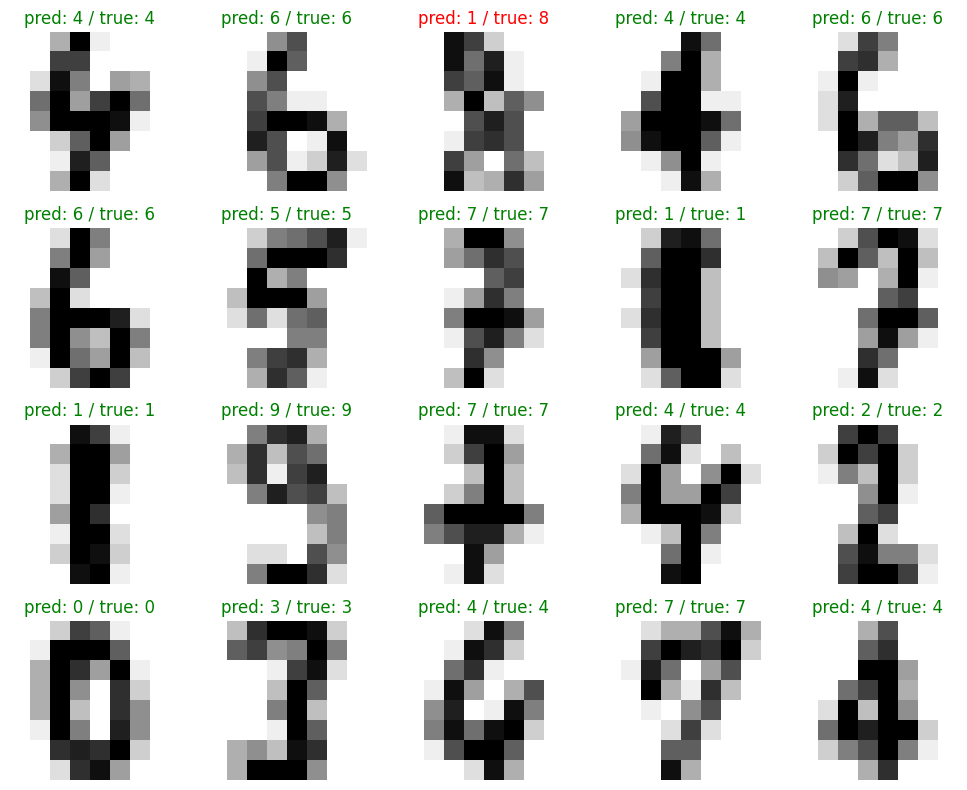

In [24]:
# 최종 결과: 테스트 이미지 20장 예측 vs 실제
fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
    color = 'green' if y_pred[i] == y_test[i] else 'red'
    ax.set_title(f"pred: {y_pred[i]} / true: {y_test[i]}", color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 실습 정리: 머신러닝(KNN) vs 딥러닝(MLP)

### 실험 조건
- 데이터: `sklearn.datasets.load_digits()` (8×8 손글씨 숫자 1797장)
- 분할: `train_test_split(test_size=0.2, random_state=42)` → 학습 1437장 / 테스트 360장
- 두 모델 모두 **같은 학습·테스트 데이터**로 학습하고 평가함
- 딥러닝은 `keras.utils.set_random_seed(42)`로 결과를 고정함

### 비교표

| 구분 | 머신러닝 (KNN) | 딥러닝 (MLP) |
|---|---|---|
| 모델 | `KNeighborsClassifier(n_neighbors=6)` | `Dense 128 → Dropout 0.2 → Dense 64 → Dense 10` |
| 학습 방식 | 학습 없이 데이터를 저장만 함 | epoch마다 가중치를 반복 조정 (50 epoch) |
| 예측 방식 | 가장 가까운 이웃 6개의 다수결 | 0~9 각각의 확률 계산 후 가장 높은 값 선택 (`argmax`) |
| 전처리 | 없음 | 정규화(`/16.0`), 원-핫 인코딩(`to_categorical`) |
| 손실 함수 | 없음 | `categorical_crossentropy` |
| 설정할 것 | `k` 하나 | 층 수, 뉴런 수, 활성화 함수, loss, optimizer, epoch 등 |
| 학습 과정 확인 | 불가 | epoch별 loss/accuracy 로그와 그래프 |
| **정확도** | **0.9889 (356/360)** | **0.9694 (349/360)** |

### 결과 분석
- 같은 조건에서 KNN이 딥러닝보다 약 2%p 높았다. 이미지로 따지면 7장 차이다.
- KNN이 더 잘 나온 이유
  - **데이터가 적다**: 학습 이미지가 1437장뿐이다. 딥러닝은 데이터가 많을수록 강하다.
  - **데이터가 단순하다**: 8×8 숫자는 비슷한 그림끼리 거리가 가까워서 "가장 비슷한 이웃 찾기"인 KNN에 유리하다.
  - **MLP는 이미지 구조를 활용하지 못한다**: 64픽셀을 일렬로 펴서 넣기 때문에 픽셀 간 위치 관계를 학습하지 못한다.
  - **하이퍼파라미터를 튜닝하지 않았다**: 층 수, 뉴런 수, epoch 등을 조정하면 성능이 오를 수 있다.

### 느낀 점
- KNN은 코드가 짧고 단순한데도 작은 데이터에서 높은 성능을 냈다.
- 딥러닝은 설정할 것이 많지만, 학습 과정을 epoch 단위로 확인하며 개선할 수 있다.
- **딥러닝이 항상 더 좋은 것은 아니다.** 데이터의 크기와 특성에 맞는 모델을 고르는 것이 중요하다.
- 공정하게 비교하려면 `random_state`로 데이터 분할을 고정해야 한다는 것을 알게 되었다.
- 더 큰 데이터(MNIST 등)나 이미지 구조를 활용하는 CNN을 쓰면 딥러닝의 장점이 더 잘 드러날 것이다.